# Points to remember:

- all the input features must be independent of each other, if in case they shows dependency we will fall into the trap of multicollinearity.
- Atleast one of the input feature must have some sort of dependency with the target feature.
- In the case of Logistic regression my input features should follow gaussian distribution.
- In this case study lot of mistake. It is not giving proper output

In [40]:
# Predict the species of the penguins

In [77]:
import pandas as pd

In [78]:
df= pd.read_csv("C:/Ruquayya Banu/Data Science/Datasets/penguins_size.csv")

In [79]:
df

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE
...,...,...,...,...,...,...,...
339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN
340,Gentoo,Biscoe,46.8,14.3,215.0,4850.0,FEMALE
341,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,MALE
342,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,FEMALE


In [80]:
df["species"].value_counts() # multi class classification

species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

In [81]:
# logistic regression are of 3 type:-
#  1) binary - having 2 categories 
#  2) multinominal - having more than 2 categories 
#  3) ordinal - all input features are of ordinal type and target feature contains orders.

In [82]:
# check basic cleaning of the data
df

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE
...,...,...,...,...,...,...,...
339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN
340,Gentoo,Biscoe,46.8,14.3,215.0,4850.0,FEMALE
341,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,MALE
342,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,FEMALE


In [83]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   culmen_length_mm   342 non-null    float64
 3   culmen_depth_mm    342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                334 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB


In [84]:
# only two rows have null values 


In [85]:
# data cleaning  start

In [86]:
# handling missing values 
# seperating numerical and categorical col

num_cols=df.select_dtypes(include=["float64"])
cat_cols=df.select_dtypes(include=["object"])

In [87]:
df["sex"].value_counts() # replace the dot with NaN and fill with mode

sex
MALE      168
FEMALE    165
.           1
Name: count, dtype: int64

In [88]:
# treat one extra category in the sex column.
df["sex"]=df["sex"].str.replace(".",df["sex"].mode()[0])

In [89]:
# treating null values numerical columns
for col in num_cols:
    df[col]=df[col].fillna(df[col].median())

In [90]:
# treating null values categorical columns
for col in cat_cols:
    df[col]=df[col].fillna(df[col].mode()[0])

In [91]:
# checking for outliers - Logistic regression is very sensitive to outliers
df.describe()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
count,344.000000,344.000000,344.000000,344.000000
mean,43.925000,17.152035,200.892442,4200.872093
std,5.443792,1.969060,14.023826,799.696532
min,32.100000,13.100000,172.000000,2700.000000
25%,39.275000,15.600000,190.000000,3550.000000
50%,44.450000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.000000,4750.000000
max,59.600000,21.500000,231.000000,6300.000000


<Axes: ylabel='Density'>

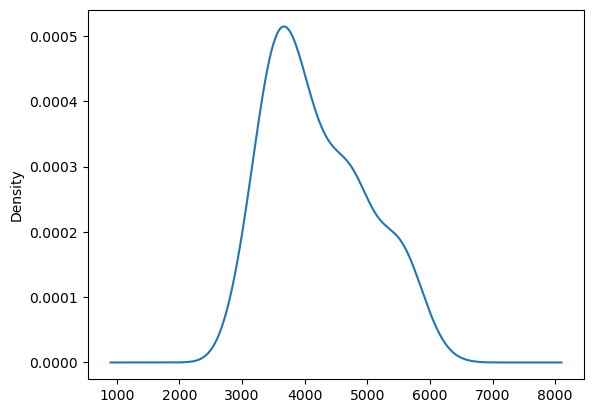

In [92]:
df["body_mass_g"].plot(kind="kde")

In [93]:
import numpy as np
def cap_outliers(col):
    Q1=df[col].quantile(0.25)
    Q3=df[col].quantile(0.75)
    IQR=Q3-Q1
    lower=Q1-1.5*IQR
    upper=Q3+1.5*IQR

    df[col]=np.where(df[col]<lower,lower,np.where(df[col]>upper,upper,df[col]))


for col in num_cols:
    cap_outliers(col)

In [94]:
Q1=df["body_mass_g"].quantile(0.25)
Q3=df["body_mass_g"].quantile(0.75)
IQR=Q3-Q1
lower=Q1-1.5*IQR
upper=Q3+1.5*IQR
df["body_mass_g"]=np.where(df["body_mass_g"]<lower,lower,np.where(df["body_mass_g"]>upper,upper,df["body_mass_g"]))


In [95]:
Q1,Q3

(np.float64(3550.0), np.float64(4750.0))

In [96]:
lower, upper

(np.float64(1750.0), np.float64(6550.0))

In [97]:
df["body_mass_g"]>upper

0      False
1      False
2      False
3      False
4      False
       ...  
339    False
340    False
341    False
342    False
343    False
Name: body_mass_g, Length: 344, dtype: bool

In [98]:
df["body_mass_g"]>upper

0      False
1      False
2      False
3      False
4      False
       ...  
339    False
340    False
341    False
342    False
343    False
Name: body_mass_g, Length: 344, dtype: bool

In [99]:
# seperating input and target feature.

x=df.iloc[:,1:]
y=df["species"]

In [100]:
x

,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Torgersen,39.10,18.7,181.0,3750.0,MALE
1,Torgersen,39.50,17.4,186.0,3800.0,FEMALE
2,Torgersen,40.30,18.0,195.0,3250.0,FEMALE
3,Torgersen,44.45,17.3,197.0,4050.0,MALE
4,Torgersen,36.70,19.3,193.0,3450.0,FEMALE
...,...,...,...,...,...,...
339,Biscoe,44.45,17.3,197.0,4050.0,MALE
340,Biscoe,46.80,14.3,215.0,4850.0,FEMALE
341,Biscoe,50.40,15.7,222.0,5750.0,MALE
342,Biscoe,45.20,14.8,212.0,5200.0,FEMALE


In [101]:
y

0      Adelie
1      Adelie
2      Adelie
3      Adelie
4      Adelie
        ...  
339    Gentoo
340    Gentoo
341    Gentoo
342    Gentoo
343    Gentoo
Name: species, Length: 344, dtype: object

In [102]:
# transforming island and Gender 
# categorical columns
from sklearn.preprocessing import OneHotEncoder

cat_col=["island","sex"]

encoder=OneHotEncoder(drop="first",sparse_output=False)
cat_encoded=encoder.fit_transform(x[cat_col])

# converting into data frame
cat_df=pd.DataFrame(cat_encoded,columns=encoder.get_feature_names_out(cat_col))

In [103]:
cat_df

,island_Dream,island_Torgersen,sex_MALE
0,0.0,1.0,1.0
1,0.0,1.0,0.0
2,0.0,1.0,0.0
3,0.0,1.0,1.0
4,0.0,1.0,0.0
...,...,...,...
339,0.0,0.0,1.0
340,0.0,0.0,0.0
341,0.0,0.0,1.0
342,0.0,0.0,0.0


In [104]:
# concatenating the encoded data into x
x=pd.concat([x,cat_df],axis=1) # axis = 1 is for column


In [105]:
x

,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex,island_Dream,island_Torgersen,sex_MALE
0,Torgersen,39.10,18.7,181.0,3750.0,MALE,0.0,1.0,1.0
1,Torgersen,39.50,17.4,186.0,3800.0,FEMALE,0.0,1.0,0.0
2,Torgersen,40.30,18.0,195.0,3250.0,FEMALE,0.0,1.0,0.0
3,Torgersen,44.45,17.3,197.0,4050.0,MALE,0.0,1.0,1.0
4,Torgersen,36.70,19.3,193.0,3450.0,FEMALE,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...
339,Biscoe,44.45,17.3,197.0,4050.0,MALE,0.0,0.0,1.0
340,Biscoe,46.80,14.3,215.0,4850.0,FEMALE,0.0,0.0,0.0
341,Biscoe,50.40,15.7,222.0,5750.0,MALE,0.0,0.0,1.0
342,Biscoe,45.20,14.8,212.0,5200.0,FEMALE,0.0,0.0,0.0


In [106]:
# island and sex column need to remove as it is not useful
x=x.drop(["island","sex"],axis=1)


In [107]:
x

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,island_Dream,island_Torgersen,sex_MALE
0,39.10,18.7,181.0,3750.0,0.0,1.0,1.0
1,39.50,17.4,186.0,3800.0,0.0,1.0,0.0
2,40.30,18.0,195.0,3250.0,0.0,1.0,0.0
3,44.45,17.3,197.0,4050.0,0.0,1.0,1.0
4,36.70,19.3,193.0,3450.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...
339,44.45,17.3,197.0,4050.0,0.0,0.0,1.0
340,46.80,14.3,215.0,4850.0,0.0,0.0,0.0
341,50.40,15.7,222.0,5750.0,0.0,0.0,1.0
342,45.20,14.8,212.0,5200.0,0.0,0.0,0.0


In [109]:
# splitting the data into train and test
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.3,random_state=7)

In [108]:
#  body_mass_g column is in gram rest all are in milimeters 
#  almost all the column is following gaussian distribution format
#  so standardization on data 

In [112]:
num_cols # all numerical columns contain

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
0,39.1,18.7,181.0,3750.0
1,39.5,17.4,186.0,3800.0
2,40.3,18.0,195.0,3250.0
3,NaN,NaN,NaN,NaN
4,36.7,19.3,193.0,3450.0
...,...,...,...,...
339,NaN,NaN,NaN,NaN
340,46.8,14.3,215.0,4850.0
341,50.4,15.7,222.0,5750.0
342,45.2,14.8,212.0,5200.0


In [110]:
# standardizing the numerical features on training data
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()

x_train[num_cols.columns]=scaler.fit_transform(x_train[num_cols.columns])

In [113]:
x_train

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,island_Dream,island_Torgersen,sex_MALE
97,-0.697288,0.647996,-0.366138,0.201212,1.0,0.0,1.0
177,1.448213,0.894071,-0.293154,-0.054464,1.0,0.0,1.0
246,0.072892,-1.419029,1.093549,-0.118384,0.0,0.0,1.0
16,-0.990690,0.894071,-0.439122,-0.949333,0.0,1.0,0.0
204,0.292943,0.057417,-0.585091,-0.757576,1.0,0.0,0.0
...,...,...,...,...,...,...,...
211,0.274606,1.090930,-0.512107,-0.853454,1.0,0.0,0.0
67,-0.550587,0.943285,-0.950013,-0.118384,0.0,0.0,1.0
25,-1.614169,0.844856,-1.022997,-0.501899,0.0,0.0,0.0
196,1.246500,0.352707,-0.366138,-0.661697,1.0,0.0,0.0


In [117]:

# standardizing the numerical features on test data
x_test[num_cols.columns]=scaler.transform(x_test[num_cols.columns])

In [115]:
x_test

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,island_Dream,island_Torgersen,sex_MALE
173,0.806397,0.155847,-0.731060,-1.013252,1.0,0.0,1.0
30,-0.843989,-0.237872,-1.679856,-1.205010,1.0,0.0,0.0
115,-0.257185,0.549566,-0.366138,-0.150343,0.0,0.0,1.0
341,1.154812,-0.730021,1.531455,1.990950,0.0,0.0,1.0
141,-0.642275,0.008202,-1.022997,-0.917374,1.0,0.0,1.0
...,...,...,...,...,...,...,...
285,1.044786,-0.188657,2.115329,1.927030,0.0,0.0,1.0
104,-1.137391,0.697211,-0.585091,-1.620485,0.0,0.0,0.0
174,-0.165497,-0.287087,-1.022997,-1.652444,1.0,0.0,0.0
52,-1.669182,0.352707,-0.804044,-0.949333,0.0,0.0,0.0


In [118]:
# logistic regression - multinominal 
# logistic regression model implementation start

In [125]:
#model implementation

from sklearn.linear_model import LogisticRegression
LR=LogisticRegression() #or -- LR=LogisticRegression(multi_class="multinomial")
# multinominal no need to mention - according to data it will take binary or multinominal or ordinal
LR.fit(x_train,y_train)

LogisticRegression()

In [126]:
# predicitng the value
y_pred=LR.predict(x_test)

In [127]:
y_pred

array(['Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie',
       'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie',
       'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie',
       'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie',
       'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie',
       'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie',
       'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie',
       'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie',
       'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie',
       'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie',
       'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie',
       'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie',
       'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie',
       'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie',
       'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adel

In [129]:
y_pred, y_test

(array(['Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie',
        'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie',
        'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie',
        'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie',
        'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie',
        'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie',
        'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie',
        'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie',
        'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie',
        'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie',
        'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie',
        'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie',
        'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie',
        'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie',
        'Adelie', 'Adelie', 'Adelie', 'Adelie', 

In [130]:
# checking the accuracy of the model

from sklearn.metrics import accuracy_score,confusion_matrix,ConfusionMatrixDisplay,classification_report
accuracy_score(y_pred,y_test)

0.46153846153846156

In [137]:
confusion_matrix(y_pred,y_test)
# first row belong to Adelie
# second row belong to Chinstrap
# third row belong to Gentoo

array([[48, 18, 38],
       [ 0,  0,  0],
       [ 0,  0,  0]])

In [138]:
# confusion matrix class name
labels=LR.classes_
labels
# first row belong to Adelie
# second row belong to Chinstrap
# third row belong to Gentoo

array(['Adelie', 'Chinstrap', 'Gentoo'], dtype=object)

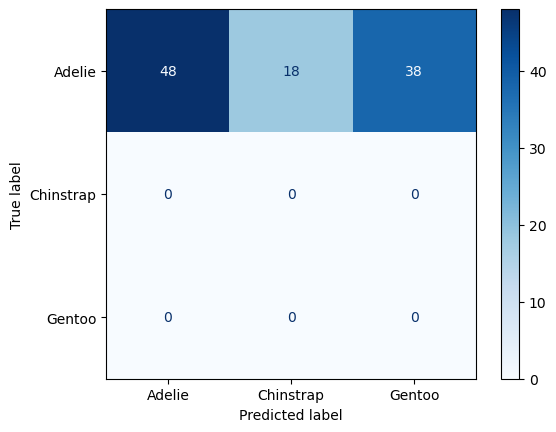

In [139]:
# to read the confusion matrix we check it in visualization form
import matplotlib.pyplot as plt
Heat=ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=labels)
Heat.plot(cmap="Blues")

In [140]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

      Adelie       0.46      1.00      0.63        48
   Chinstrap       0.00      0.00      0.00        18
      Gentoo       0.00      0.00      0.00        38

    accuracy                           0.46       104
   macro avg       0.15      0.33      0.21       104
weighted avg       0.21      0.46      0.29       104



C:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
